In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import preprocessing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

# 读取清洗好的part2
df = pd.read_csv("dataset_part_2.csv")
df.head()

,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0


In [7]:
# 挑选用来建模的特征
features = df[['PayloadMass', 'Orbit', 'LaunchSite', 'Flights', 'GridFins',
               'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial']]
# 目标标签
Y = df['Class']

# 类别特征独热编码
features_one_hot = pd.get_dummies(features, columns=['Orbit','LaunchSite','LandingPad','Serial'])

# 保存编码后的数据集 dataset_part_3.csv
features_one_hot.to_csv("dataset_part_3.csv", index=False)
print("✅ dataset_part_3.csv 生成完成！")
X = features_one_hot
X.head()

✅ dataset_part_3.csv 生成完成！


,PayloadMass,Flights,GridFins,Reused,Legs,Block,ReusedCount,Orbit_ES-L1,Orbit_GEO,Orbit_GTO,...,Serial_B1048,Serial_B1049,Serial_B1050,Serial_B1051,Serial_B1054,Serial_B1056,Serial_B1058,Serial_B1059,Serial_B1060,Serial_B1062
0,6104.959412,1,False,False,False,1.0,0,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,525.000000,1,False,False,False,1.0,0,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,677.000000,1,False,False,False,1.0,0,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,500.000000,1,False,False,False,1.0,0,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,3170.000000,1,False,False,False,1.0,0,False,False,True,...,False,False,False,False,False,False,False,False,False,False


In [8]:
# 标准化
transformer = preprocessing.StandardScaler()
X = transformer.fit_transform(X)

# 划分数据集，20%做测试集
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=2)
print(f"训练集大小：{X_train.shape}, 测试集大小：{X_test.shape}")

训练集大小：(72, 79), 测试集大小：(18, 79)


In [11]:
def plot_confusion_matrix(y_true, y_pred, model_name):
    cm = confusion_matrix(y_true, y_pred)
    ax = plt.subplot()
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)
    ax.set_xlabel('Predicted label')
    ax.set_ylabel('True label')
    ax.set_title(f'{model_name} Confusion Matrix')
    plt.show()

Logistic Regression 最优参数： {'C': 0.1}
Logistic Regression 测试集准确率： 0.9444444444444444


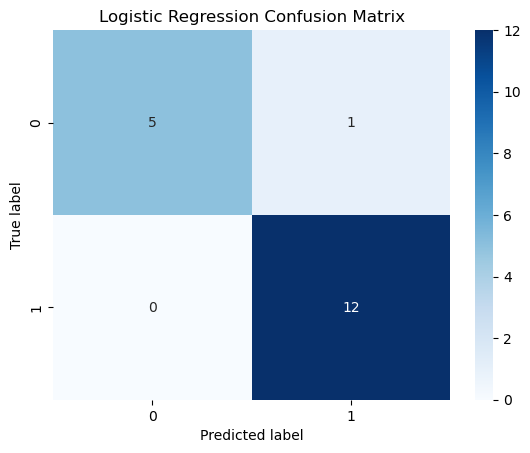

In [12]:
lr = LogisticRegression(max_iter=1000)
lr_params = {"C":[0.01,0.1,1,10]}
lr_cv = GridSearchCV(lr, lr_params, cv=5)
lr_cv.fit(X_train,Y_train)
lr_best = lr_cv.best_estimator_
lr_pred = lr_best.predict(X_test)
print("Logistic Regression 最优参数：", lr_cv.best_params_)
print("Logistic Regression 测试集准确率：", lr_best.score(X_test,Y_test))
plot_confusion_matrix(Y_test, lr_pred, "Logistic Regression")

SVM 最优参数： {'C': 0.1, 'kernel': 'linear'}
SVM 测试集准确率： 0.9444444444444444


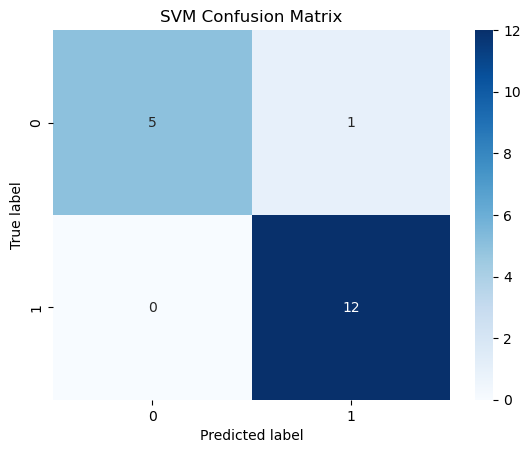

In [15]:
svm = SVC()
svm_params = {"kernel":['linear','rbf'], "C":[0.1,1,10]}
svm_cv = GridSearchCV(svm, svm_params, cv=5)
svm_cv.fit(X_train,Y_train)
svm_best = svm_cv.best_estimator_
svm_pred = svm_best.predict(X_test)
print("SVM 最优参数：", svm_cv.best_params_)
print("SVM 测试集准确率：", svm_best.score(X_test,Y_test))
plot_confusion_matrix(Y_test, svm_pred, "SVM")

Decision Tree 最优参数： {'criterion': 'gini', 'max_depth': 2}
Decision Tree 测试集准确率： 0.8888888888888888


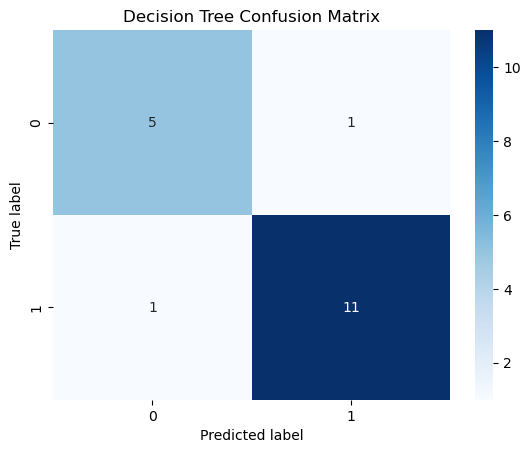

In [16]:
tree = DecisionTreeClassifier()
tree_params = {"criterion":['gini','entropy'], "max_depth":[2,4,6,8]}
tree_cv = GridSearchCV(tree, tree_params, cv=5)
tree_cv.fit(X_train,Y_train)
tree_best = tree_cv.best_estimator_
tree_pred = tree_best.predict(X_test)
print("Decision Tree 最优参数：", tree_cv.best_params_)
print("Decision Tree 测试集准确率：", tree_best.score(X_test,Y_test))
plot_confusion_matrix(Y_test, tree_pred, "Decision Tree")

C:\Users\lenovo\anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] 系统找不到指定的文件。
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\lenovo\anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\lenovo\anaconda\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\lenovo\anaconda\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\lenovo\anaconda\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
       

KNN 最优参数： {'n_neighbors': 3}
KNN 测试集准确率： 0.6666666666666666


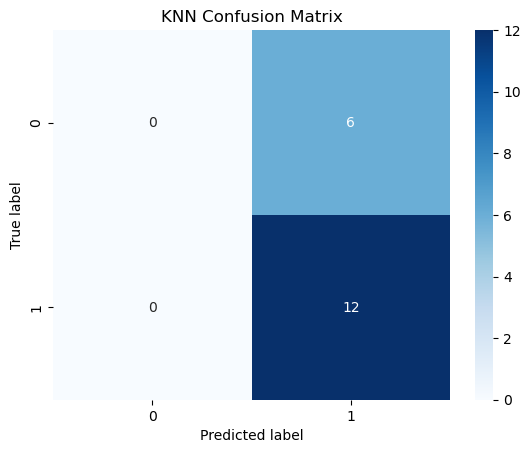

In [17]:
knn = KNeighborsClassifier()
knn_params = {"n_neighbors":[3,5,7,9]}
knn_cv = GridSearchCV(knn, knn_params, cv=5)
knn_cv.fit(X_train,Y_train)
knn_best = knn_cv.best_estimator_
knn_pred = knn_best.predict(X_test)
print("KNN 最优参数：", knn_cv.best_params_)
print("KNN 测试集准确率：", knn_best.score(X_test,Y_test))
plot_confusion_matrix(Y_test, knn_pred, "KNN")

In [18]:
score_dict = {
    "Logistic Regression": lr_best.score(X_test,Y_test),
    "SVM": svm_best.score(X_test,Y_test),
    "Decision Tree": tree_best.score(X_test,Y_test),
    "KNN": knn_best.score(X_test,Y_test)
}
score_df = pd.DataFrame(list(score_dict.items()),columns=['Model','Accuracy'])
score_df.sort_values("Accuracy", ascending=False)

,Model,Accuracy
0,Logistic Regression,0.944444
1,SVM,0.944444
2,Decision Tree,0.888889
3,KNN,0.666667
